# B1.3 Euler Angles and Rigid Body Orientation

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.1 Motivation — Why Do We Need Euler Angles?

Imagine taking a photograph of a spinning gyroscope. The direction of the shaft tells you how the wheel is tilted, but you also need to see a mark on the rim to tell how far the wheel has turned about the shaft. Those observations describe its **orientation** at the instant of the photograph. A sequence of photographs lets you determine how that orientation is changing.

A rotation matrix describes the orientation by giving the directions of the body axes in the space frame. **Euler angles** describe the same orientation using three successive rotations. For a gyroscope, these rotations have a geometric interpretation: turn around the vertical, tilt the shaft, then turn the wheel about the shaft.

<img src="fig1.3.1.png" width="1000" alt="Euler Angles in Science"/>

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.2 Learning Objectives

By the end of this lesson, you should be able to:

- Identify the space, intermediate, and body axes used in the intrinsic $ZXZ$ convention.
- Construct the line of nodes and use measured body directions to determine the Euler angles.
- Build the body-to-space rotation matrix and use it to express a vector in either frame.
- Distinguish steady precession, nutation, and spin by describing what happens to the shaft and a mark on the wheel.
- Express angular velocity in terms of the Euler-angle rates and resolve it into body components.
- Explain what becomes redundant at gimbal lock and identify the angle combination that still determines the orientation.

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.3 What Are Euler Angles?

Choose a right-handed **space frame** $(x_S,y_S,z_S)$ fixed in the laboratory and a right-handed **body frame** $(x_B,y_B,z_B)$ attached to the rigid body. For a gyroscope, we can take $z_S$ vertically upward, $z_B$ along the shaft toward a marked end, and $x_B$ from the center of the wheel toward a mark on the rim. Then $\hat{\mathbf y}_B=\hat{\mathbf z}_B\times\hat{\mathbf x}_B$.

To construct the body orientation, start with the moving axes aligned with the space axes and apply three positive right-hand rotations in the order below. A negative angle reverses the corresponding rotation.

| Step | Angle | Rotation axis | What the rotation sets |
|---|---|---|---|
| 1 | $\phi$ | Fixed vertical $z_S$ | The direction of the intermediate axis $x'$ in the lab horizontal plane (Precession)|
| 2 | $\theta$ | Intermediate axis $x'$ | The tilt of the shaft $z_B$ from the vertical (Nutation)|
| 3 | $\psi$ | Final shaft axis $z_B$ | The direction of $x_B$ around the shaft (Spin)|

This sequence is **intrinsic** because each rotation uses the axes as they stand at that stage. The first rotation carries the moving $x$ axis to $x'$. The second leaves $x'$ in place and carries the moving $z$ axis to $z_B$. The third leaves $z_B$ in place and carries the moving $x$ axis from $x'$ to $x_B$. In an **extrinsic** description, each rotation is about an axis fixed in space. The choice of axes and their order are both part of the convention.

<img src="fig1-A2.3.png" width="800" alt="Space and body frames with the Euler rotation axes"/>

Figure taken from [Wolfram Alpha](https://mathworld.wolfram.com/EulerAngles.html)

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.4 Finding the Three Rotation Axes

### Choose the space and body directions

The first axis, $\hat{\mathbf z}_S$, comes from the choice of laboratory frame. The third axis, $\hat{\mathbf z}_B$, comes from the choice of body frame and the body's observed orientation. For the gyroscope, these directions are vertical and along the shaft, respectively.

### Construct the intermediate axis

Draw the lab horizontal plane and the plane of the wheel through a common origin at the wheel center. The two planes have normals $\hat{\mathbf z}_S$ and $\hat{\mathbf z}_B$. Their intersection is the **line of nodes**. Its direction lies in both planes, so it is perpendicular to both normals.

<div style="background-color:#e6f0ff; border-left:6px solid #003366; padding:12px; border-radius:4px;">
<strong>Positive direction of the line of nodes</strong>

For $0<\theta<\pi$, the intrinsic $ZXZ$ convention takes

$$
\boxed{
\hat{\mathbf n}=\hat{\mathbf x}'
=\frac{\hat{\mathbf z}_S\times\hat{\mathbf z}_B}
{\left|\hat{\mathbf z}_S\times\hat{\mathbf z}_B\right|}.
}
$$

The cross product sets the sign so that a positive rotation about $\hat{\mathbf n}$ carries $\hat{\mathbf z}_S$ toward $\hat{\mathbf z}_B$ through the tilt angle $\theta$.

</div>

Although $\hat{\mathbf n}$ is perpendicular to both $z$ directions, those two directions make an angle $\theta$ with each other. The three Euler rotation axes therefore form an orthogonal set only when $\theta=90^\circ$.

### Read the angles from the axes

- **$\phi$** is the signed angle from $\hat{\mathbf x}_S$ to $\hat{\mathbf n}$ about $\hat{\mathbf z}_S$.
- **$\theta$** is the angle from $\hat{\mathbf z}_S$ to $\hat{\mathbf z}_B$, with $\cos\theta=\hat{\mathbf z}_S\cdot\hat{\mathbf z}_B$. Measure $\phi$ to the line of nodes. The horizontal projection of the shaft points $90^\circ$ clockwise from that line's positive direction when viewed from above.
- **$\psi$** is the signed angle from $\hat{\mathbf n}$ to $\hat{\mathbf x}_B$ about $\hat{\mathbf z}_B$, measured in the wheel plane.

When the shaft is vertical, the two planes coincide and the cross product vanishes. In that orientation, the geometry leaves the line of nodes undetermined.

---

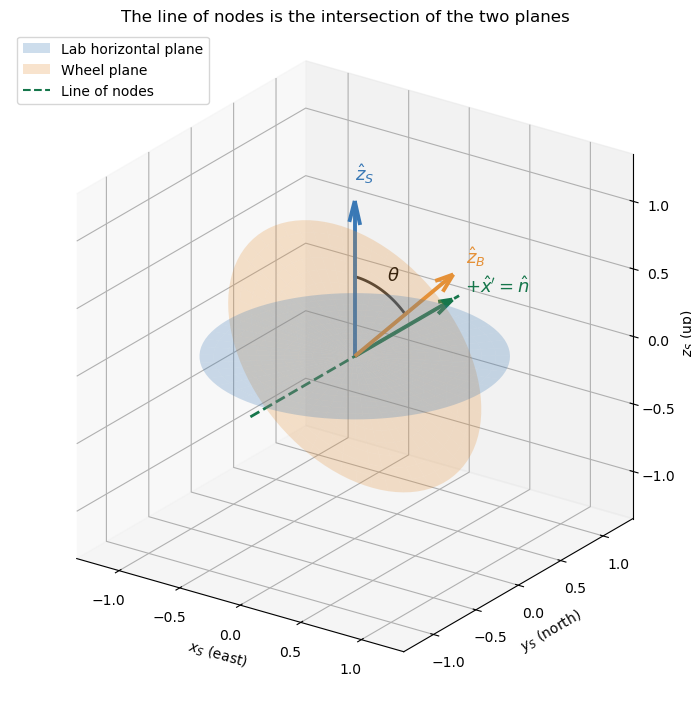

Positive x′ direction in lab coordinates: [0. 1. 0.]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# B1.3.4 — Construct the intermediate axis and show the line of nodes.
# The default angles give a shaft tilted 45° from vertical toward east.
phi_deg = 90
theta_deg = 45
phi, theta = np.deg2rad([phi_deg, theta_deg])

z_space = np.array([0.0, 0.0, 1.0])
z_body = np.array([
    np.sin(phi) * np.sin(theta),
    -np.cos(phi) * np.sin(theta),
    np.cos(theta),
])

# The cross product lies in both planes and selects the positive x′ direction.
cross = np.cross(z_space, z_body)
cross_length = np.linalg.norm(cross)

if cross_length < 1e-10:
    raise ValueError(
        "The two planes coincide at this tilt. The line of nodes is undefined."
    )

node = cross / cross_length

# Each plane contains the line of nodes and a second in-plane direction.
horizontal_side = np.cross(z_space, node)
wheel_side = np.cross(z_body, node)

radius = 1.05
r, angle = np.meshgrid(
    np.linspace(0, radius, 12),
    np.linspace(0, 2 * np.pi, 100),
)

fig = plt.figure(figsize=(9, 7), layout="constrained")
ax = fig.add_subplot(projection="3d")

lab_color = "#3978b5"
wheel_color = "#e59138"
node_color = "#16764b"

# Draw the lab horizontal plane and wheel plane as translucent disks.
for side, color in [(horizontal_side, lab_color), (wheel_side, wheel_color)]:
    disk = (
        (r * np.cos(angle))[..., None] * node
        + (r * np.sin(angle))[..., None] * side
    )
    ax.plot_surface(
        disk[..., 0],
        disk[..., 1],
        disk[..., 2],
        color=color,
        alpha=0.25,
        linewidth=0,
        shade=False,
    )

# The dashed line shows the intersection in both directions.
line = np.array([-1.23, 1.23])[:, None] * node
ax.plot(*line.T, "--", color=node_color, linewidth=2)

# The arrows show the two plane normals and the positive x′ direction.
for direction, label, color in [
    (z_space, r"$\hat{z}_S$", lab_color),
    (z_body, r"$\hat{z}_B$", wheel_color),
    (node, r"$+\hat{x}'=\hat{n}$", node_color),
]:
    ax.quiver(
        0, 0, 0, *direction,
        length=1.15,
        color=color,
        linewidth=2.8,
        arrow_length_ratio=0.15,
    )
    ax.text(*(1.30 * direction), label, color=color, fontsize=13)

# Draw the tilt angle from the lab vertical toward the shaft.
toward_shaft = np.cross(node, z_space)
arc_angles = np.linspace(0, theta, 60)
arc = 0.59 * (
    np.cos(arc_angles)[:, None] * z_space
    + np.sin(arc_angles)[:, None] * toward_shaft
)
ax.plot(*arc.T, color="#333333", linewidth=2)
ax.text(*(1.16 * arc[len(arc) // 2]), r"$\theta$", fontsize=13)

ax.set(
    xlim=(-1.35, 1.35),
    ylim=(-1.35, 1.35),
    zlim=(-1.35, 1.35),
    xlabel=r"$x_S$ (east)",
    ylabel=r"$y_S$ (north)",
    zlabel=r"$z_S$ (up)",
    title="The line of nodes is the intersection of the two planes",
)
ax.set_box_aspect((1, 1, 1))
ax.set_proj_type("ortho")
ax.view_init(elev=24, azim=-55)

ax.legend(
    handles=[
        Patch(facecolor=lab_color, alpha=0.25, label="Lab horizontal plane"),
        Patch(facecolor=wheel_color, alpha=0.25, label="Wheel plane"),
        Line2D([0], [0], color=node_color, linestyle="--", label="Line of nodes"),
    ],
    loc="upper left",
)

plt.show()

# Suppress signed zeros when displaying the rounded components.
node_display = np.round(node, 3) + 0.0
print("Positive x′ direction in lab coordinates:", node_display)

---

**Check your reasoning.** Both directions along the dashed line lie in both planes. Which direction does $\hat{\mathbf z}_S\times\hat{\mathbf z}_B$ select? Use the right-hand rule to check that a positive rotation about that direction carries $\hat{\mathbf z}_S$ toward $\hat{\mathbf z}_B$.

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.5 Box Activity — Find the Euler Axes of a Gyroscope

<div style="background-color:#e8f5e9; border-left:6px solid #006633; padding:14px; border-radius:4px;">
<h3 style="margin-top:0;">Reconstruct the orientation from a camera snapshot</h3>

A camera measures the direction toward the marked end of a gyroscope shaft and the direction from the center of the wheel to a painted dot on its rim. Take the fixed lab axes to be $x_S$ east, $y_S$ north, and $z_S$ up. The measured body directions in lab coordinates are

$$
[\hat{\mathbf z}_B]_S=\frac{1}{\sqrt{2}}(1,0,1),
\qquad
[\hat{\mathbf x}_B]_S=\frac{1}{\sqrt{2}}(-1,0,1).
$$

Use the intrinsic $z_S$–$x'$–$z_B$ convention.

1. Sketch the shaft, the plane of the wheel, and the lab horizontal plane through the center of the wheel. Along which lab axis do the planes intersect?
2. Find all three Euler rotation axes as unit vectors in lab coordinates. Use a cross product to choose the positive direction of the line of nodes.
3. Starting with the body and lab axes aligned, find the three successive rotations $(\phi,\theta,\psi)$ that reproduce the snapshot. Explain how you know the sign of $\psi$.
4. Suppose the painted dot is hidden. Which angles can you still recover from the shaft direction? What motion could a video of the shaft alone miss?

<details>
<summary style="background-color:#006633; color:white; padding:8px; border-radius:4px; cursor:pointer;">
Activity solution
</summary>

**1. Find the intersection.** The shaft lies in the east–up plane. The north–south direction is horizontal and perpendicular to the shaft, so it lies in both planes. The line of nodes is along the $y_S$ axis.

**2. Choose the positive axes.** The cross product $\hat{\mathbf z}_S\times\hat{\mathbf z}_B$ gives $(0,1,0)/\sqrt{2}$ in lab coordinates. The positive line of nodes points north. The three unit directions in lab coordinates are

$$
[\hat{\mathbf z}_S]_S=(0,0,1),\qquad
[\hat{\mathbf n}]_S=(0,1,0),\qquad
[\hat{\mathbf z}_B]_S=\frac{1}{\sqrt{2}}(1,0,1).
$$

**3. Recover the angles.** Turn from east to north about the upward vertical, giving $\phi=90^\circ$. Then turn about the northward axis to tilt the shaft toward east. Since $\hat{\mathbf z}_S\cdot\hat{\mathbf z}_B=1/\sqrt{2}$, the tilt is $\theta=45^\circ$. This second rotation leaves the intermediate $x$ axis pointing north. For the final turn, use the right-hand rule about the shaft:

$$
[\hat{\mathbf z}_B\times\hat{\mathbf n}]_S
=\frac{1}{\sqrt{2}}(-1,0,1)
=[\hat{\mathbf x}_B]_S.
$$

The dot is exactly one positive quarter turn from the line of nodes in the wheel plane. Therefore $\psi=+90^\circ$, giving

$$
\boxed{(\phi,\theta,\psi)=(90^\circ,45^\circ,90^\circ).}
$$

**4. Hide the dot.** In this orientation, the shaft direction fixes the tilt $\theta$ and the line of nodes, which gives $\phi$. The position of the dot around the shaft fixes $\psi$. The wheel can spin while its shaft points in a constant direction, so a video that tracks only the shaft can miss that spin entirely.

</details>
</div>

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.6 The ZXZ Rotation Matrix

Let $R$ map the components of a vector from the body frame to the space frame. Its columns are the three body unit axes expressed in the space frame:

$$
R=
\begin{bmatrix}
[\hat{\mathbf x}_B]_S & [\hat{\mathbf y}_B]_S & [\hat{\mathbf z}_B]_S
\end{bmatrix},
\qquad
[\mathbf v]_S=R[\mathbf v]_B,
\qquad
[\mathbf v]_B=R^T[\mathbf v]_S.
$$

The elementary right-hand rotation matrices are

$$
R_z(\alpha)=
\begin{bmatrix}
\cos\alpha&-\sin\alpha&0\\
\sin\alpha&\cos\alpha&0\\
0&0&1
\end{bmatrix},
\qquad
R_x(\beta)=
\begin{bmatrix}
1&0&0\\
0&\cos\beta&-\sin\beta\\
0&\sin\beta&\cos\beta
\end{bmatrix}.
$$

Starting at $R=I$, the first rotation sets the frame orientation to $R_z(\phi)$. Each later rotation is specified in the current moving frame, so its matrix multiplies on the right. Thus,

$$
\boxed{R=R_z(\phi)R_x(\theta)R_z(\psi).}
$$

**Which rotation comes first?** In the intrinsic $ZXZ$ construction, $\phi$ comes first because we are building the orientation of the moving frame. We turn by $\phi$ about $z_S$, then by $\theta$ about the newly positioned $x'$, and finally by $\psi$ about the shaft $z_B$. When we evaluate the matrix product $R\mathbf v=R_z(\phi)R_x(\theta)R_z(\psi)\mathbf v$, however, the rightmost factor $R_z(\psi)$ acts on the column vector first. If we interpret that multiplication as an active rotation with all axes held fixed, the equivalent sequence is $\psi$ about $z_S$, then $\theta$ about $x_S$, then $\phi$ about $z_S$. Both sequences produce the same final rotation because reversing the order here goes together with switching from moving axes to fixed axes.

---

<div style="background-color:#e8f5e9; border-left:6px solid #006633; padding:14px; border-radius:4px;">
<h3 style="margin-top:0;">Box Activity — Check the matrix against the gyroscope geometry</h3>

Multiply the three matrices. Use the third column to explain why the shaft direction is independent of $\psi$. Then substitute the angles from the camera snapshot and check the first and third columns.

<details>
<summary style="background-color:#006633; color:white; padding:8px; border-radius:4px; cursor:pointer;">
Activity solution
</summary>

With $c_\alpha=\cos\alpha$ and $s_\alpha=\sin\alpha$, the product is

$$
R=
\begin{bmatrix}
c_\phi c_\psi-s_\phi c_\theta s_\psi &
-c_\phi s_\psi-s_\phi c_\theta c_\psi &
s_\phi s_\theta\\
s_\phi c_\psi+c_\phi c_\theta s_\psi &
-s_\phi s_\psi+c_\phi c_\theta c_\psi &
-c_\phi s_\theta\\
s_\theta s_\psi & s_\theta c_\psi & c_\theta
\end{bmatrix}.
$$

The third column depends only on $\phi$ and $\theta$. Geometrically, the last rotation turns the wheel about its own shaft and leaves the shaft direction unchanged. For $(90^\circ,45^\circ,90^\circ)$, the first and third columns are $(-1,0,1)^T/\sqrt{2}$ and $(1,0,1)^T/\sqrt{2}$, matching the measured dot and shaft directions.

</details>
</div>

---

<div style="background-color:#e8f5e9; border-left:6px solid #006633; padding:14px; border-radius:4px;">
<h3 style="margin-top:0;">Box Activity — Where Does the Robot’s Laser Hit?</h3>

A robot wrist carries a laser rangefinder that checks the position of a part on an assembly table. The laser points along the wrist’s positive $x_B$ axis and reports a range of $2.00\,\mathrm{m}$. The beam starts at the wrist origin, whose lab coordinates are $(1.00,0.50,1.00)\,\mathrm{m}$. The lab axes point east ($x_S$), north ($y_S$), and up ($z_S$).

The wrist’s orientation is given by the intrinsic $ZXZ$ Euler angles

$$
(\phi,\theta,\psi)=(90^\circ,30^\circ,-90^\circ),
\qquad
R=R_z(\phi)R_x(\theta)R_z(\psi).
$$

1. Write the displacement vector from the laser to the hit point in **wrist coordinates**.
2. Compute that displacement in **lab coordinates**. Apply one matrix at a time and record the intermediate column vectors. Which factor acts first?
3. Find the lab coordinates of the hit point. The assembly table is at $z_S=0$. Is the reading consistent with a hit on the tabletop?
4. The robot constructs the wrist orientation by turning through $\phi$ first. Explain why your calculation starts with the $\psi$ factor.

<details>
<summary style="background-color:#006633; color:white; padding:8px; border-radius:4px; cursor:pointer;">
Activity solution
</summary>

**1. Write the measured displacement.** The beam travels $2.00\,\mathrm{m}$ along positive $x_B$, so

$$
[\Delta\mathbf r]_B=
\begin{bmatrix}2\\0\\0\end{bmatrix}\mathrm{m}.
$$

**2. Apply the rotation matrix one factor at a time.** The rightmost factor acts first on the column vector. The intermediate columns below are in meters.

$$
\begin{bmatrix}2\\0\\0\end{bmatrix}
\xrightarrow{\ R_z(-90^\circ)\ }
\begin{bmatrix}0\\-2\\0\end{bmatrix}
\xrightarrow{\ R_x(30^\circ)\ }
\begin{bmatrix}0\\-\sqrt{3}\\-1\end{bmatrix}
\xrightarrow{\ R_z(90^\circ)\ }
\begin{bmatrix}\sqrt{3}\\0\\-1\end{bmatrix}.
$$

The beam therefore travels about $1.73\,\mathrm{m}$ east and $1.00\,\mathrm{m}$ down. Its displacement still has magnitude $\sqrt{3+1}\,\mathrm{m}=2.00\,\mathrm{m}$, as expected for a rotation.

**3. Locate the hit.** Add the rotated displacement to the laser’s lab position:

$$
[\mathbf r_{\mathrm{hit}}]_S
=
\begin{bmatrix}1.00\\0.50\\1.00\end{bmatrix}\mathrm{m}
+
\begin{bmatrix}\sqrt{3}\\0\\-1\end{bmatrix}\mathrm{m}
\approx
\boxed{\begin{bmatrix}2.73\\0.50\\0.00\end{bmatrix}\mathrm{m}}.
$$

The hit point is at tabletop height, so the reading is consistent with a hit on the tabletop.

**4. Explain the two orders.** The wrist orientation is constructed by turning through $\phi$ about the lab vertical, then through $\theta$ about the moved $x'$ axis, and finally through $\psi$ about the wrist’s final $z_B$ axis. In the calculation, we start with components in the **finished wrist frame** and use $R$ to express the same beam displacement in the lab frame. The rightmost factor acts first because it takes us from the final wrist basis back to the basis just before the last turn.

</details>
</div>

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.7 Precession, Nutation, and Spin

### Precession changes the direction around the vertical

When $\phi(t)$ changes, the shaft sweeps around the fixed vertical. The shaft's horizontal projection and the line of nodes turn together. If $\theta$ stays constant, the tip of the shaft direction traces a circle on the unit sphere and the shaft sweeps out a cone. When $\dot\phi$ is constant as well, the precession is uniform.

### Nutation changes the tilt

The angle $\theta$ measures the tilt at an instant. **Nutation** is the variation of that tilt over time, often an oscillation in which the shaft alternately leans farther from the vertical and comes closer to it. The instantaneous rotation that changes the tilt is about the line of nodes, with rate $\dot\theta$.

For example, suppose a video gives

$$
\phi(t)=\Omega t,
\qquad
\theta(t)=30^\circ+5^\circ\cos(\nu t),
$$

where $\Omega$ is the precession rate and $\nu$ is the angular frequency of the tilt oscillation. The shaft sweeps around the vertical while its tilt varies between $25^\circ$ and $35^\circ$. At each extreme, $\dot\theta=0$ for an instant while precession continues. A video can therefore show nutation even when a single frame taken at a turning point gives no instantaneous change in tilt.

[Cool video on nutation](https://www.youtube.com/watch?v=5Sn2J1Vn4zU)

**When is nutation undesirable?** Nutation is a normal part of rotational motion. A spinning top can keep spinning and precessing while its tilt angle $\theta$ oscillates. Whether that oscillation matters depends on what the system needs to do. For a tabletop demonstration, it makes the changing tilt easy to see. For a camera or antenna that must stay aimed at a target, the same oscillation can cause a pointing error. Even a balanced rotor can nutate after a brief torque disturbs its motion.

### Spin turns the wheel about the shaft

The angle $\psi$ locates the painted dot relative to the line of nodes in the wheel plane. Changing $\psi$ turns the wheel about $z_B$ and leaves the shaft direction fixed for that contribution. When precession occurs at the same time, the total angular velocity along the shaft also contains the projection $\dot\phi\cos\theta$. We derive that projection below.

<div style="background-color:#e8f5e9; border-left:6px solid #006633; padding:14px; border-radius:4px;">
<h3 style="margin-top:0;">Box Activity — Diagnose the motion from a video</h3>

A gyroscope's shaft sweeps around the vertical. Its tilt repeats the sequence $25^\circ$, $35^\circ$, $25^\circ$. A dot on the rim also makes repeated turns relative to the line of nodes. Which Euler angles are changing? What happens to the nutation contribution to angular velocity when the tilt reaches $35^\circ$?

<details>
<summary style="background-color:#006633; color:white; padding:8px; border-radius:4px; cursor:pointer;">
Activity solution
</summary>

The sweep around the vertical means $\phi$ changes. The repeated change in tilt means $\theta$ changes, so the shaft nutates as it precesses. The dot turning relative to the line of nodes means $\psi$ changes. At a smooth maximum of the tilt, $\dot\theta=0$, so the instantaneous nutation contribution vanishes. Precession and spin can continue through that instant.

</details>
</div>

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.8 Angular Velocity in Space and Body Coordinates

### Add the three instantaneous rotations

During a short time interval $dt$, the Euler angles change by $d\phi$, $d\theta$, and $d\psi$. Each change contributes a small rotation about its own instantaneous axis. To first order in $dt$, these small rotation vectors add. Dividing by $dt$ gives

$$
\boxed{
\boldsymbol{\omega}
=
\dot{\phi}\,\hat{\mathbf z}_S
+
\dot{\theta}\,\hat{\mathbf n}
+
\dot{\psi}\,\hat{\mathbf z}_B.
}
$$

The three terms are the contributions from precession about the lab vertical, nutation about the line of nodes, and spin about the shaft. Evaluate all three axis directions at the same instant.

<div style="background-color:#e6f0ff; border-left:6px solid #003366; padding:12px; border-radius:4px;">
<strong>Axis names and component labels</strong>

The boxed equation is a geometric vector equation. The subscript in $\hat{\mathbf z}_S$ identifies the **lab vertical**, and the subscript in $\hat{\mathbf z}_B$ identifies the **shaft direction**. Either direction can be expressed in either basis. The subscript outside the brackets tells you which basis you are using. For example, $[\hat{\mathbf z}_S]_B$ means the lab vertical expressed in body coordinates. To add component columns, first express all three directions in the same basis.

</div>

### Express angular velocity in space coordinates

In the lab basis, the vertical is $(0,0,1)^T$. The line of nodes lies in the horizontal plane and makes a signed angle $\phi$ with $x_S$. The shaft direction is the third column of the body-to-space matrix $R$ from B1.3.6. Thus,

$$
[\boldsymbol{\omega}]_S
=
\dot{\phi}
\begin{bmatrix}0\\0\\1\end{bmatrix}
+
\dot{\theta}
\begin{bmatrix}\cos\phi\\\sin\phi\\0\end{bmatrix}
+
\dot{\psi}
\begin{bmatrix}
\sin\phi\sin\theta\\
-\cos\phi\sin\theta\\
\cos\theta
\end{bmatrix}.
$$

For example, the vertical component is $\omega_{z_S}=\dot{\phi}+\dot{\psi}\cos\theta$. The spin term contributes to this component because the shaft has a projection along the vertical.

### Express angular velocity in body coordinates

We can obtain $[\boldsymbol{\omega}]_B$ by applying $R^T$ to the space components. We can also project each rotation axis directly onto the body axes. The second approach makes the signs and the axial projection easier to see.

- **Shaft axis.** The shaft defines the body's positive $z$ axis, so $[\hat{\mathbf z}_B]_B=(0,0,1)^T$.
- **Line of nodes.** The final rotation carries $\hat{\mathbf n}$ to $\hat{\mathbf x}_B$ through $+\psi$ about $\hat{\mathbf z}_B$. To locate $\hat{\mathbf n}$ in the finished body frame, start at $\hat{\mathbf x}_B$ and turn back through $-\psi$. This gives $[\hat{\mathbf n}]_B=(\cos\psi,-\sin\psi,0)^T$.
- **Lab vertical.** Since $R$ maps body components to space components, $R^T(0,0,1)^T$ gives the lab vertical in body coordinates. This selects the third row of $R$ and writes it as a column. Its last entry is $\hat{\mathbf z}_S\cdot\hat{\mathbf z}_B=\cos\theta$.

Combining the three contributions gives

$$
\boxed{
[\boldsymbol{\omega}]_B
=
\begin{bmatrix}
\dot{\theta}\cos\psi+\dot{\phi}\sin\theta\sin\psi\\
-\dot{\theta}\sin\psi+\dot{\phi}\sin\theta\cos\psi\\
\dot{\psi}+\dot{\phi}\cos\theta
\end{bmatrix}.
}
$$

The axial component $\omega_{z_B}$ includes both the spin rate $\dot{\psi}$ and the projection of the precession contribution onto the shaft. The nutation contribution has zero projection along the shaft because the line of nodes is perpendicular to it.

<div style="background-color:#e8f5e9; border-left:6px solid #006633; padding:14px; border-radius:4px;">
<h3 style="margin-top:0;">Box Activity — Fill In the Gaps in the Body-Frame Calculation</h3>

A gyroscope is precessing, nutating, and spinning. At one instant, $\theta=60^\circ$ and $\psi=90^\circ$. The measured Euler-angle rates are

$$
\dot{\phi}=2\,\mathrm{rad/s},
\qquad
\dot{\theta}=1\,\mathrm{rad/s},
\qquad
\dot{\psi}=5\,\mathrm{rad/s}.
$$

1. Use the geometry to fill in the **body components** of the shaft and the line of nodes. Sketch the wheel plane and explain the sign of the nonzero component of $\hat{\mathbf n}$.

$$
[\hat{\mathbf z}_B]_B=
\begin{bmatrix}\square\\\square\\\square\end{bmatrix},
\qquad
[\hat{\mathbf n}]_B=
\begin{bmatrix}\square\\\square\\\square\end{bmatrix}.
$$

2. Read the third row of $R$ from B1.3.6 and substitute the given angles to fill in the lab vertical in body coordinates.

$$
[\hat{\mathbf z}_S]_B=
\begin{bmatrix}\square\\\square\\\square\end{bmatrix}.
$$

3. Multiply each direction by its corresponding Euler-angle rate. Fill in the contribution from each rotation and add the columns.

$$
[\boldsymbol{\omega}]_B
=
\underbrace{\begin{bmatrix}\square\\\square\\\square\end{bmatrix}}_{\text{precession}}
+
\underbrace{\begin{bmatrix}\square\\\square\\\square\end{bmatrix}}_{\text{nutation}}
+
\underbrace{\begin{bmatrix}\square\\\square\\\square\end{bmatrix}}_{\text{spin}}
=
\begin{bmatrix}\square\\\square\\\square\end{bmatrix}
\mathrm{rad/s}.
$$

4. Your axial component should differ from $5\,\mathrm{rad/s}$. Which rotation supplies the difference, and why?

<details>
<summary style="background-color:#006633; color:white; padding:8px; border-radius:4px; cursor:pointer;">
Activity solution
</summary>

**1. Locate the shaft and the line of nodes.** The shaft is the positive body $z$ axis. Since $\psi=90^\circ$, a positive quarter turn about the shaft carries $\hat{\mathbf n}$ into $\hat{\mathbf x}_B$. Starting at $\hat{\mathbf x}_B$ and reversing that turn points along $-\hat{\mathbf y}_B$. Therefore,

$$
[\hat{\mathbf z}_B]_B=
\begin{bmatrix}0\\0\\1\end{bmatrix},
\qquad
[\hat{\mathbf n}]_B=
\begin{bmatrix}0\\-1\\0\end{bmatrix}.
$$

**2. Project the lab vertical onto the body axes.** The third row of $R$ contains the vertical component of each body axis. Those three projections are also the body components of the lab vertical:

$$
[\hat{\mathbf z}_S]_B
=
\begin{bmatrix}
\sin 60^\circ\sin 90^\circ\\
\sin 60^\circ\cos 90^\circ\\
\cos 60^\circ
\end{bmatrix}
=
\begin{bmatrix}\sqrt{3}/2\\0\\1/2\end{bmatrix}.
$$

**3. Add the contributions in a common basis.**

$$
[\boldsymbol{\omega}]_B
=
\left(
\begin{bmatrix}\sqrt{3}\\0\\1\end{bmatrix}
+
\begin{bmatrix}0\\-1\\0\end{bmatrix}
+
\begin{bmatrix}0\\0\\5\end{bmatrix}
\right)\mathrm{rad/s}
=
\boxed{
\begin{bmatrix}\sqrt{3}\\-1\\6\end{bmatrix}\mathrm{rad/s}
}.
$$

**4. Explain the extra axial angular velocity.** Precession contributes $\dot{\phi}\cos\theta=(2)(1/2)=1\,\mathrm{rad/s}$ along the shaft. Together with the $5\,\mathrm{rad/s}$ from spin, this gives $\omega_{z_B}=6\,\mathrm{rad/s}$. Nutation acts along the line of nodes and contributes only in the wheel plane.

</details>
</div>

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.9 Gimbal Lock — When Two Angle Changes Share an Axis

In the $ZXZ$ convention, gimbal lock occurs at $\theta=0$ and $\theta=\pi$. The first and third rotation axes lie on the same line. Changing $\phi$ or $\psi$ produces rotation about that common axis line, so the two angle changes cease to provide independent instantaneous rotation directions. The line of nodes also becomes undetermined because $\hat{\mathbf z}_S\times\hat{\mathbf z}_B=\mathbf 0$.

### Shaft pointing up — only the sum determines the orientation

At $\theta=0$, the shaft and the lab vertical point in the same direction. The middle rotation is the identity, and the two turns about the vertical add:

$$
R(\phi,0,\psi)=R_z(\phi)R_z(\psi)=R_z(\phi+\psi).
$$

The three angle triples from the slide discussion,

$$
(35^\circ,0^\circ,15^\circ),\qquad
(30^\circ,0^\circ,20^\circ),\qquad
(40^\circ,0^\circ,10^\circ),
$$

all give $R=R_z(50^\circ)$. In every case the shaft points up and the dot ends up $50^\circ$ counterclockwise from east when viewed from above. You can move $5^\circ$ from one angle to the other and get exactly the same photograph.

### Shaft pointing down — only the difference determines the orientation

At $\theta=\pi$, the shaft and the lab vertical point in opposite directions. A positive turn about the downward shaft has the opposite sense to a positive turn about the upward vertical. Using $R_x(\pi)R_z(\psi)=R_z(-\psi)R_x(\pi)$ gives

$$
R(\phi,\pi,\psi)=R_z(\phi-\psi)R_x(\pi).
$$

The orientation therefore depends on $\phi-\psi$. Adding the same amount to both angles leaves the orientation unchanged.

<div style="background-color:#ffe6e6; border-left:6px solid #cc0000; padding:14px; border-radius:4px;">
<strong>Danger — The Euler-angle coordinates become singular</strong>

A freely rotating body retains its physical rotational freedom. The singularity lies in the angle description. For a fixed choice of angle triple at the pole, $\dot\phi$ and $\dot\psi$ give only one independent direction, and $\dot\theta$ supplies one transverse direction. The rate-to-angular-velocity map therefore has rank two there. Rotation matrices and unit quaternions can describe the orientation through these poses without this Euler-angle singularity.

</div>

---

<div style="background-color:#e8f5e9; border-left:6px solid #006633; padding:14px; border-radius:4px;">
<h3 style="margin-top:0;">Box Activity — Make two angle changes cancel</h3>

Hold $\theta=0$. Starting at $(\phi,\psi)=(35^\circ,15^\circ)$, increase $\phi$ by $5^\circ$ while decreasing $\psi$ by $5^\circ$. Where do the shaft and the dot end up? Would the same changes cancel if you held the shaft at $\theta=45^\circ$?

<details>
<summary style="background-color:#006633; color:white; padding:8px; border-radius:4px; cursor:pointer;">
Activity solution
</summary>

At $\theta=0$, the shaft remains vertical and the dot remains $50^\circ$ from east. The two turns act about the same axis in opposite senses. Equivalently, the angular velocity during the adjustment is $(\dot\phi+\dot\psi)\hat{\mathbf z}_S=\mathbf 0$ if the changes are made at equal and opposite rates.

At $\theta=45^\circ$, changing $\phi$ sweeps the tilted shaft around the vertical. Changing $\psi$ turns the wheel about the tilted shaft and leaves that shaft direction fixed. The second change therefore cannot undo the change in shaft direction caused by the first.

</details>
</div>

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.10 Yaw, Pitch, and Roll — A Different Rotation Sequence

Imagine an aircraft with its nose pointing north, its right wing pointing east, and its body $z$ axis pointing down. These directions define a right-handed body frame. Let the fixed space axes point north ($x_S$), east ($y_S$), and down ($z_S$), so the two frames coincide when the aircraft is level and pointing north.

A common way to describe the aircraft's orientation is the intrinsic **$ZYX$ yaw–pitch–roll convention**. As in $ZXZ$, each turn uses the axes as they stand at that step.

| Step | Angle | Rotation axis | Positive rotation from the preceding orientation |
|---|---|---|---|
| 1 | Yaw $\alpha$ | Fixed vertical $z_S$ | Turns the nose toward the right. |
| 2 | Pitch $\beta$ | Intermediate lateral axis $y'$ | Raises the nose. |
| 3 | Roll $\gamma$ | Final longitudinal axis $x_B$ | Lowers the right wing. |

The body-to-space matrix is

$$
R_{\mathrm{YPR}}=R_z(\alpha)R_y(\beta)R_x(\gamma).
$$

Yaw comes first when constructing the moving frame. When evaluating $R_{\mathrm{YPR}}[\mathbf v]_B$, the rightmost factor $R_x(\gamma)$ acts on the component column first.

### How does this differ from $ZXZ$?

| | Intrinsic $ZXZ$ | Intrinsic $ZYX$ |
|---|---|---|
| Successive axes | $z_S \rightarrow x' \rightarrow z_B$ | $z_S \rightarrow y' \rightarrow x_B$ |
| What the middle angle measures | $\theta$ is the tilt between $z_S$ and $z_B$. | $\beta$ is the elevation of the nose above the horizontal. |
| What the final turn leaves fixed | $\psi$ turns the wheel around its shaft and leaves $z_B$ fixed. | $\gamma$ banks the aircraft around its nose-to-tail axis and leaves $x_B$ fixed. |
| Where gimbal lock occurs | At $\theta=0^\circ$ or $180^\circ$, $z_B$ lies on the same line as $z_S$. | At $\beta=\pm90^\circ$, $x_B$ lies on the same line as $z_S$. |

Picture the aircraft pointing straight up. Its roll axis is now vertical, so yaw and roll act about the same axis line. This is the same geometry that produced gimbal lock for the vertical gyroscope shaft. The two conventions reach that alignment at different values of their middle angle because their final rotation axes are different.

<div style="background-color:#e6f0ff; border-left:6px solid #003366; padding:12px; border-radius:4px;">
<strong>One orientation, two sets of angles</strong>

Both conventions can describe the same body orientation. To express a $ZXZ$ orientation in yaw, pitch, and roll, first build its rotation matrix. Then find the $ZYX$ angles that reproduce that matrix. Simply relabeling $\phi$, $\theta$, and $\psi$ as yaw, pitch, and roll generally gives a different orientation.

</div>

The intrinsic $ZYX$ yaw–pitch–roll convention is a **Tait–Bryan** (or **Cardan**) sequence because it uses three distinct axis labels. The $ZXZ$ convention is a **proper Euler-angle** sequence because it repeats the $Z$ label, using the space $z_S$ axis first and the body $z_B$ axis last.

[Video explaining ZYX convention](https://www.youtube.com/watch?v=BczeMqU_u2Y)

<hr style="height:2px;border-width:0;color:gray;background-color:gray">

## B1.3.11 Summary

| Quantity | Axis or frame | What to look for |
|---|---|---|
| $\phi$ | Fixed vertical $z_S$ | The line of nodes turns in the horizontal plane as the shaft precesses. |
| $\theta$ | Intermediate axis $x'=\hat{\mathbf n}$ | The tilt changes when the shaft nutates. |
| $\psi$ | Body shaft $z_B$ | A mark on the wheel turns relative to the line of nodes. |
| $R=R_z(\phi)R_x(\theta)R_z(\psi)$ | Body to space | The columns give the body axes in space components. |
| $\boldsymbol{\omega}=\dot\phi\hat{\mathbf z}_S+\dot\theta\hat{\mathbf n}+\dot\psi\hat{\mathbf z}_B$ | Resolve all three terms in one basis | Each angle rate contributes along its own instantaneous axis. |
| Gimbal lock | $z_S$ and $z_B$ lie on the same axis line | At $\theta=0$ the orientation depends on $\phi+\psi$. At $\theta=\pi$ it depends on $\phi-\psi$. |

<hr style="height:2px;border-width:0;color:gray;background-color:gray">